In [1]:

import pandas as pd 
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
#! pip install scikeras tensorflow
#! pip install tensorflow scikit-learn
import numpy as np
import cv2
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Dropout, Flatten, Dense, MaxPool2D
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.initializers import glorot_uniform
from tensorflow.keras.optimizers import Adam, SGD
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tensorflow.keras.regularizers import l2

from tensorflow.keras.callbacks import EarlyStopping


In [2]:
######BELLOW HERE IS TEST 
import os
import numpy as np
from sklearn.utils import shuffle
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


#  some SETTINGS
IMAGE_SIZE = (64, 64)
BASE_DIR = os.path.expanduser(
    r"Drowsiness_dataset_new\Drowsiness_dataset_new"

)
BATCH_SIZE  = 32
EPOCHS      = 10
AUG_PER_IMG = 2   # augmentations per original image

# 2) LOAD IMAGES (Closed vs Open)
def load_images(folder):
    X, y = [], []
    for cls, label in [('Closed', 0), ('Open', 1)]:
        path = os.path.join(folder, cls)
        for fname in os.listdir(path):
            try:
                img = load_img(os.path.join(path, fname), target_size=IMAGE_SIZE)
                arr = img_to_array(img) / 255.0
                X.append(arr)
                y.append(label)
            except:
                pass
    return np.array(X), np.array(y)

x_train, y_train = load_images(os.path.join(BASE_DIR, 'train'))
x_test,  y_test  = load_images(os.path.join(BASE_DIR, 'test'))

# 3) parameters for augmenations 
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
aug_X, aug_y = [], []
for img, label in zip(x_train, y_train):
    for _ in range(AUG_PER_IMG):
        aug_X.append(datagen.random_transform(img))
        aug_y.append(label)

x_train = np.vstack([x_train, np.array(aug_X)])
y_train = np.concatenate([y_train, np.array(aug_y)])
x_train, y_train = shuffle(x_train, y_train, random_state=42)

# build a random model
model = Sequential([
    Conv2D(32, 3, activation='relu', padding='same', input_shape=(*IMAGE_SIZE, 3)),
    MaxPooling2D(),
    Conv2D(64, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(128, 3, activation='relu', padding='same'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# train and capture the history for graphs et..
history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

#  EVALUATE ON TEST SET
loss, acc = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
print(f"\nTest accuracy: {acc:.3f}")

#PREDICT with percentage of confidence
print("\nPredictions with confidence:")
for i, (img, true_lbl) in enumerate(zip(x_test, y_test)):
    p_open = model.predict(img[np.newaxis, ...])[0,0]
    if p_open > 0.5:
        pred_label = 'Open'
        confidence = p_open
    else:
        pred_label = 'Closed'
        confidence = 1 - p_open
    print(f"Image {i:03d}: Predicted={pred_label} ({confidence*100:.1f}%) | True={'Open' if true_lbl else 'Closed'}")





c:\Users\dimit\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.6610 - loss: 0.5669 - val_accuracy: 0.9231 - val_loss: 0.2073
Epoch 2/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.9379 - loss: 0.1867 - val_accuracy: 0.9433 - val_loss: 0.1327
Epoch 3/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9654 - loss: 0.1057 - val_accuracy: 0.9636 - val_loss: 0.1153
Epoch 4/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.9646 - loss: 0.0987 - val_accuracy: 0.9690 - val_loss: 0.0751
Epoch 5/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.9763 - loss: 0.0600 - val_accuracy: 0.9703 - val_loss: 0.0662
Epoch 6/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.9837 - loss: 0.0602 - val_accuracy: 0.9717 - val_loss: 0.0540
Epoch 7/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9882 - loss: 0.0365 - val_accuracy: 0.9811 - val_loss: 0.0438
Epoch 8/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.9879 - loss: 0.0385 - val_accuracy: 0.9798 - v

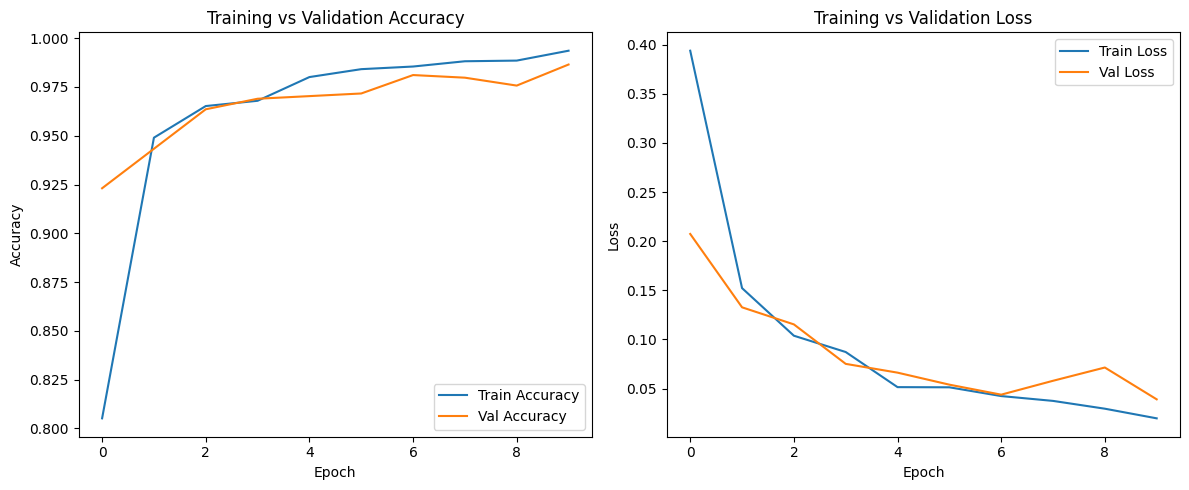

In [3]:
#PLOT TRAIN vs VAL ACCURACY & LOSS
plt.figure(figsize=(12, 5))
#make the bellow plots to make sure it doesnt overfit
# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [4]:
#WE CAN see from the graphs and from the matrix bellow , the model doesnt overfit , and performs well , thus we dont need to 
#perform different techniques like penalising large weights , l2 reuglarizaion ,more augmenations  etc etc... to make it to perform better ,
#it is alrfeady good 

In [5]:
from sklearn.metrics import confusion_matrix, classification_report

#lets adda confusion amtrix as well
# get predicted labels (0/1) for the whole test set
y_pred_probs = model.predict(x_test, batch_size=BATCH_SIZE).flatten()
y_pred = (y_pred_probs > 0.5).astype(int)

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# precision, recall, f1
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Closed', 'Open']
))



7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Confusion Matrix:
[[108   1]
 [  2 107]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.98      0.99      0.99       109
        Open       0.99      0.98      0.99       109

    accuracy                           0.99       218
   macro avg       0.99      0.99      0.99       218
weighted avg       0.99      0.99      0.99       218



In [6]:
#plotted also valdvstrain accuracy and loss  curves to make sure they dont overfit

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


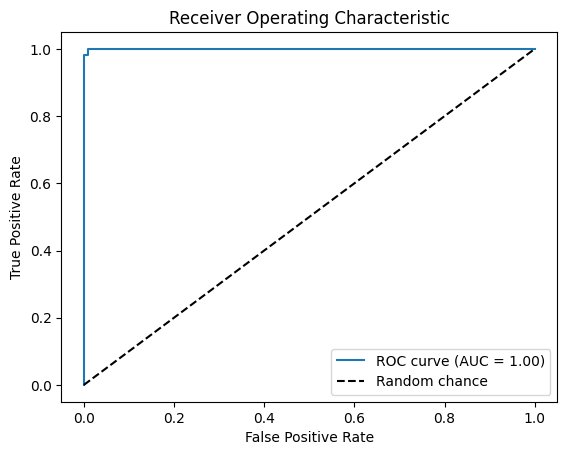

In [7]:
# ROC CURVE
from sklearn.metrics import roc_curve, auc

# get predicted probabilities for the positive class (Open)
y_pred_probs = model.predict(x_test, batch_size=BATCH_SIZE).flatten()

# compute fpr, tpr and ROC AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_probs)
roc_auc = auc(fpr, tpr)

# plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()


In [8]:
#Saving model for later use 
model.save("eye_state_model.keras") 

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,426,245 (13.07 MB)

 Trainable params: 1,142,081 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,284,164 (8.71 MB)

In [10]:
#LETS give it a test with an image that is hard to detect if it is open or closed and see how it performs 


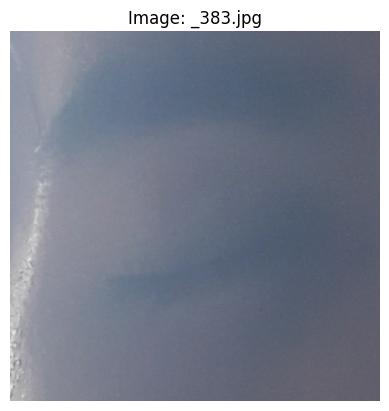

In [11]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# 1) Point to your dataset base
BASE_DIR = os.path.expanduser(
    r"Drowsiness_dataset_new\Drowsiness_dataset_new"
)

# 2) Path to the image you want to see
img_path = os.path.join(BASE_DIR, "test", "Closed", "_383.jpg")

# 3) Load & display
img = Image.open(img_path)
plt.imshow(img)
plt.axis('off')
plt.title(f"Image: {os.path.basename(img_path)}")
plt.show()
#As can be seen bellow the image looks like a snail or something 

In [12]:
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1) Config
BASE_DIR   = os.path.expanduser(
    r"Drowsiness_dataset_new\Drowsiness_dataset_new"
)
MODEL_PATH = "eye_state_model.keras"       # your saved model file
IMAGE_SIZE = (64, 64)

#doad the saved model
model = load_model(MODEL_PATH)

#pick one image from the test set
#  
img_path = os.path.join(BASE_DIR, "test", "Closed", "_383.jpg")
#img_path = os.path.join(BASE_DIR, "test", "Open", "eye17.jpg")

#preprocess loaded image as before 
img = load_img(img_path, target_size=IMAGE_SIZE)
x   = img_to_array(img) / 255.0            # normalize to [0,1]
x   = np.expand_dims(x, axis=0)            # shape (1,64,64,3)

# 5) Predict
p_open   = model.predict(x)[0,0]           # sigmoid output = P(Open)
p_closed = 1.0 - p_open                    # P(Closed)

# 6) Decide label & print
if p_open > p_closed:
    label, confidence = "Open", p_open
else:
    label, confidence = "Closed", p_closed

print(f"File:       {img_path}")
print(f"P(Open):    {p_open:.3f}")
print(f"P(Closed):  {p_closed:.3f}")
print(f"Prediction: {label} ({confidence*100:.1f}% confidence)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
File:       Drowsiness_dataset_new\Drowsiness_dataset_new\test\Closed\_383.jpg
P(Open):    0.024
P(Closed):  0.976
Prediction: Closed (97.6% confidence)


In [13]:
#As can be seen the model returns that the eye is closed with quite a good accuracy

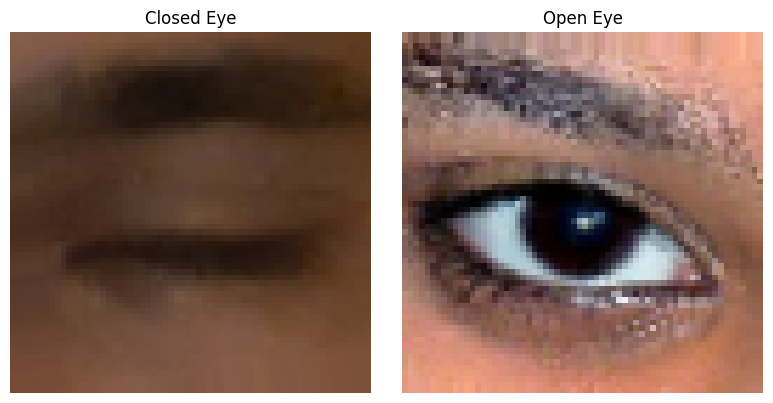

In [14]:
#Random images import matplotlib.pyplot as plt

# Convert grayscale (128,128,1) to (128,128) for display
def show_image(image):
    if image.shape[-1] == 1:
        image = image.squeeze()
    plt.imshow(image, cmap='gray')
    plt.axis('off')

# Find indices for Open and Closed eye samples
open_index = next(i for i, label in enumerate(y_train) if label == 1)
closed_index = next(i for i, label in enumerate(y_train) if label == 0)

# Plot them
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
show_image(x_train[closed_index])
plt.title("Closed Eye")

plt.subplot(1, 2, 2)
show_image(x_train[open_index])
plt.title("Open Eye")

plt.tight_layout()
plt.show()


In [15]:
#UNDER HERE IS FOR YAWNING , 

In [16]:
#lets now detect from an image the eye region

In [17]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from matplotlib import pyplot as plt


In [18]:
eye_model = load_model('eye_state_model.keras')
input_size = 64  


In [19]:
#face detector
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')


Loaded mouth patches — train: (1233, 64, 64, 3), test: (215, 64, 64, 3)
After augmentation: (3699, 64, 64, 3)


c:\Users\dimit\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,116,801 (8.07 MB)

 Trainable params: 2,116,801 (8.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
93/93 - 6s - 64ms/step - accuracy: 0.7256 - loss: 0.5177 - val_accuracy: 0.9203 - val_loss: 0.2110
Epoch 2/10
93/93 - 5s - 50ms/step - accuracy: 0.9138 - loss: 0.2153 - val_accuracy: 0.9514 - val_loss: 0.1339
Epoch 3/10
93/93 - 5s - 50ms/step - accuracy: 0.9405 - loss: 0.1513 - val_accuracy: 0.9514 - val_loss: 0.1218
Epoch 4/10
93/93 - 5s - 56ms/step - accuracy: 0.9611 - loss: 0.1104 - val_accuracy: 0.9689 - val_loss: 0.0867
Epoch 5/10
93/93 - 5s - 57ms/step - accuracy: 0.9733 - loss: 0.0889 - val_accuracy: 0.9730 - val_loss: 0.0778
Epoch 6/10
93/93 - 5s - 50ms/step - accuracy: 0.9757 - loss: 0.0728 - val_accuracy: 0.9635 - val_loss: 0.0892
Epoch 7/10
93/93 - 5s - 53ms/step - accuracy: 0.9841 - loss: 0.0531 - val_accuracy: 0.9730 - val_loss: 0.0752
Epoch 8/10
93/93 - 5s - 56ms/step - accuracy: 0.9872 - loss: 0.0379 - val_accuracy: 0.9689 - val_loss: 0.0652
Epoch 9/10
93/93 - 5s - 49ms/step - accuracy: 0.9936 - loss: 0.0239 - val_accuracy: 0.9770 - val_loss: 0.0701
Epoch 10/1

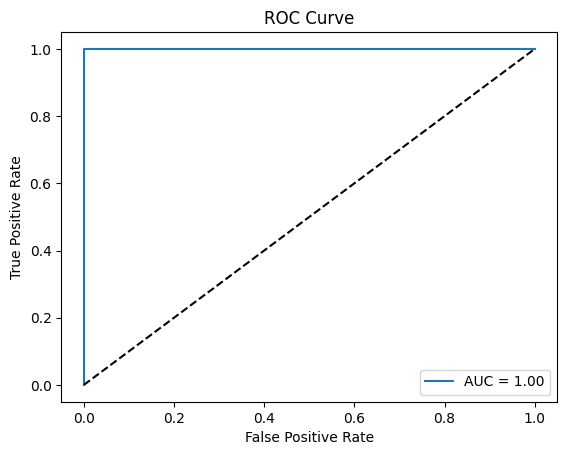

Saved model to yawn_mouth_simple_cnn.keras


In [20]:
import os
import cv2
import numpy as np
import mediapipe as mp
from sklearn.utils import shuffle
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────────────────────────────────────
#  SETTINGS & PATHS
# ──────────────────────────────────────────────────────────────────────────────
IMAGE_SIZE   = (64, 64)
BASE_DIR     = os.path.expanduser(
    r"Drowsiness_dataset_new\Drowsiness_dataset_new"
)
TRAIN_DIR    = os.path.join(BASE_DIR, "train")
TEST_DIR     = os.path.join(BASE_DIR, "test")
BATCH_SIZE   = 32
EPOCHS       = 10
AUG_PER_IMG  = 2  # fewer for speed

# ──────────────────────────────────────────────────────────────────────────────
#  MEDIAPIPE FACE DETECTION FOR MOUTH CROP
# ──────────────────────────────────────────────────────────────────────────────
mp_fd = mp.solutions.face_detection
fd    = mp_fd.FaceDetection(min_detection_confidence=0.5)

def crop_mouth(img_bgr):
   #i want to detect the lower 40% of the face
    h, w = img_bgr.shape[:2]
    rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    dets = fd.process(rgb).detections
    if not dets:
        return None
    bb     = dets[0].location_data.relative_bounding_box
    x0, y0 = int(bb.xmin * w), int(bb.ymin * h)
    bw, bh = int(bb.width * w), int(bb.height * h)
    y1     = y0 + bh
    ystart = y0 + int(0.4 * bh)
    roi    = img_bgr[ystart:y1, x0:x0 + bw]
    if roi.size == 0:
        return None
    return cv2.resize(roi, IMAGE_SIZE)

# ──────────────────────────────────────────────────────────────────────────────
# LOAD & CROP YAWN DATASET
# ──────────────────────────────────────────────────────────────────────────────
def load_mouth_data(folder):
    X, y = [], []
    for cls, label in [("no_yawn", 0), ("yawn", 1)]:
        cls_dir = os.path.join(folder, cls)
        for fn in os.listdir(cls_dir):
            img = cv2.imread(os.path.join(cls_dir, fn))
            if img is None:
                continue
            mouth = crop_mouth(img)
            if mouth is None:
                continue
            mouth_rgb = cv2.cvtColor(mouth, cv2.COLOR_BGR2RGB) / 255.0
            X.append(mouth_rgb)
            y.append(label)
    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.int32)
    return X, y

x_train, y_train = load_mouth_data(TRAIN_DIR)
x_test,  y_test  = load_mouth_data(TEST_DIR)
print(f"Loaded mouth patches — train: {x_train.shape}, test: {x_test.shape}")

# ──────────────────────────────────────────────────────────────────────────────
#  DATA AUGMENTATION
# ──────────────────────────────────────────────────────────────────────────────
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

aug_X, aug_y = [], []
for img, lbl in zip(x_train, y_train):
    for _ in range(AUG_PER_IMG):
        aug_X.append(datagen.random_transform(img))
        aug_y.append(lbl)

aug_X = np.array(aug_X, dtype=np.float32)
aug_y = np.array(aug_y, dtype=np.int32)

x_train = np.vstack([x_train, aug_X])
y_train = np.concatenate([y_train, aug_y])
x_train, y_train = shuffle(x_train, y_train, random_state=42)
print(f"After augmentation: {x_train.shape}")

# ──────────────────────────────────────────────────────────────────────────────
#  VERIFY DTYPE
# ──────────────────────────────────────────────────────────────────────────────
x_train = x_train.astype(np.float32)
y_train = y_train.astype(np.int32)
assert x_train.dtype == np.float32, f"x_train dtype is {x_train.dtype}"
assert y_train.dtype == np.int32,   f"y_train dtype is {y_train.dtype}"

# ──────────────────────────────────────────────────────────────────────────────
#  BUILD SIMPLE CNN
# ──────────────────────────────────────────────────────────────────────────────
model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(*IMAGE_SIZE,3)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid'),
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# ──────────────────────────────────────────────────────────────────────────────
#  TRAIN and save histry
# ──────────────────────────────────────────────────────────────────────────────
history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)

# ──────────────────────────────────────────────────────────────────────────────
# evaluatE
# ──────────────────────────────────────────────────────────────────────────────
loss, acc = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE, verbose=0)
print(f"\nTest accuracy: {acc:.3f}")

y_probs = model.predict(x_test, batch_size=BATCH_SIZE).flatten()
y_pred  = (y_probs > 0.5).astype(int)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['no_yawn','yawn']))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curve"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# SAVE MODEL
# ──────────────────────────────────────────────────────────────────────────────
model.save("yawn_mouth_simple_cnn2.keras")
print("Saved model to yawn_mouth_simple_cnn.keras")


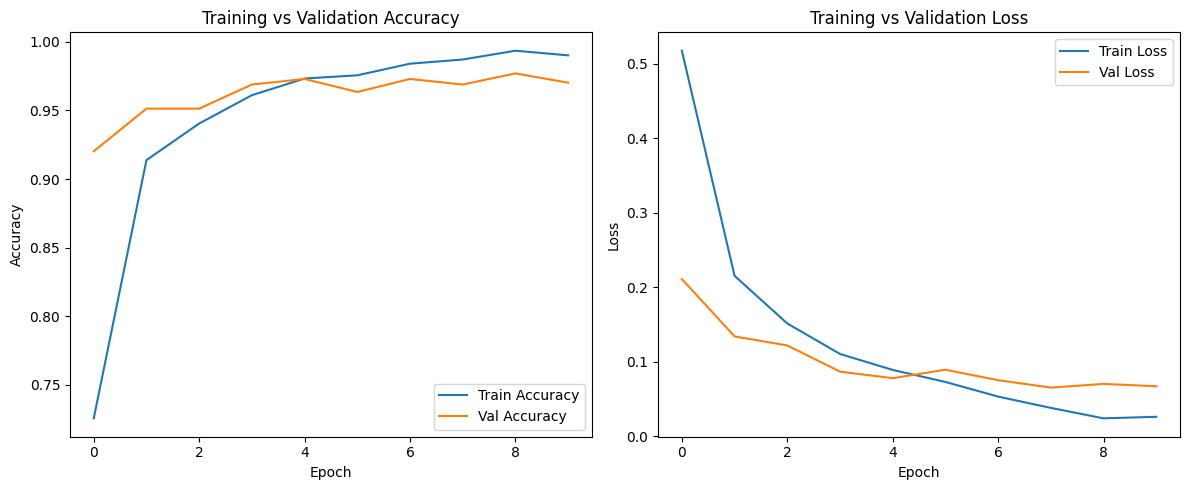

In [21]:
#PLOT TRAIN vs VAL ACCURACY & LOSS
plt.figure(figsize=(12, 5))
#make the bellow plots to make sure it doesnt overfit
# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import confusion_matrix, classification_report

#lets adda confusion amtrix as well
# get predicted labels (0/1) for the whole test set
y_pred_probs = model.predict(x_test, batch_size=BATCH_SIZE).flatten()
y_pred = (y_pred_probs > 0.5).astype(int)

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# precision, recall, f1
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Closed', 'Open']
))



7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Confusion Matrix:
[[109   0]
 [  0 106]]

Classification Report:
              precision    recall  f1-score   support

      Closed       1.00      1.00      1.00       109
        Open       1.00      1.00      1.00       106

    accuracy                           1.00       215
   macro avg       1.00      1.00      1.00       215
weighted avg       1.00      1.00      1.00       215



In [23]:
#TEST 7/7 
import mediapipe as mp
from collections import deque

mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=False,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

def get_mar(landmarks, image_shape):
    """
    Compute the Mouth Aspect Ratio (vertical/horizontal).
    Uses landmarks 13 (upper lip), 14 (lower lip), 78 & 308 (corners).
    """
    h, w = image_shape[:2]
    pts = lambda i: np.array([landmarks[i].x * w, landmarks[i].y * h])
    upper   = pts(13)
    lower   = pts(14)
    left    = pts(78)
    right   = pts(308)
    vertical   = np.linalg.norm(upper - lower)
    horizontal = np.linalg.norm(left - right)
    return vertical / horizontal if horizontal > 0 else 0


In [24]:
MAR_THRESHOLD       = 0.6   # minimal mouth opening to even consider a yawn
YAWN_PROB_THRESHOLD = 0.8   # only high-confidence CNN yawns pass
EYE_PROB_THRESHOLD  = 0.5   # tweak if your eye model is too sensitive
SMOOTHING_WINDOW    = 10    # rolling window over last N frames

# deques for temporal smoothing
yawn_history = deque(maxlen=SMOOTHING_WINDOW)
eye_history  = deque(maxlen=SMOOTHING_WINDOW)


In [25]:
import cv2
import numpy as np
import mediapipe as mp
from tensorflow.keras.models import load_model
import time
from collections import deque

# ---------- Load models ----------
eye_model  = load_model('eye_state_model.keras')
yawn_model = load_model('yawn_mouth_simple_cnn2.keras')
input_size = 64  # both models trained on (64,64,3)

# ---------- Initialize Mediapipe Face Mesh ----------
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=False,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

# ---------- Thresholds & smoothing ----------
FPS                    = 30   # approximate webcam FPS
EYE_CLOSED_THRESHOLD   =  FPS      # 2 seconds eye closed is drawziness
YAWN_HANGOVER_FRAMES   = 2 * FPS          # “hold” yawn status for 2s
MAR_THRESHOLD          = 0.6          # minimal mouth opening ratio
YAWN_PROB_THRESHOLD    = 0.8          # require high CNN confidence be high
closed_eyes_frames     = 0
yawn_hangover_counter  = 0

# ---------- MAR helper ----------
def get_mar(landmarks, shape):
    h, w = shape[:2]
    # landmarks: 13 (upper lip), 14 (lower lip), 78 & 308 (corners)
    pts = lambda i: np.array([landmarks[i].x * w, landmarks[i].y * h])
    vertical   = np.linalg.norm(pts(13) - pts(14))
    horizontal = np.linalg.norm(pts(78) - pts(308))
    return vertical / horizontal if horizontal > 0 else 0

# ---------- Detection function ----------
def detect_and_classify(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    res = face_mesh.process(rgb)

    eyes_closed = False
    yawn_now   = False

    if res.multi_face_landmarks:
        lm = res.multi_face_landmarks[0].landmark

        # --- EYES DETECTION as before ---
        closed_count = 0
        for indices, label in zip(
            [[33,133,160,159,158,157,173,246],
             [362,263,387,386,385,384,398,466]],
            ['Left','Right']
        ):
            xs = [int(lm[i].x * frame.shape[1]) for i in indices]
            ys = [int(lm[i].y * frame.shape[0]) for i in indices]
            x1, x2 = max(min(xs)-5,0), min(max(xs)+5,frame.shape[1])
            y1, y2 = max(min(ys)-5,0), min(max(ys)+5,frame.shape[0])
            eye = frame[y1:y2, x1:x2]
            try:
                img = cv2.resize(cv2.cvtColor(eye, cv2.COLOR_BGR2RGB),
                                 (input_size,input_size)) / 255.0
                pred = eye_model.predict(img[np.newaxis], verbose=0)[0,0]
                if pred <= 0.5:
                    closed_count += 1
                cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0),2)
                cv2.putText(frame, f"{label} Eye:{'Closed' if pred<=0.5 else 'Open'}",
                            (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5,(0,255,0),2)
            except:
                pass
        eyes_closed = (closed_count == 2)

        # --- MOUTH / YAWN DETECTION with MAR filter ---
        mar = get_mar(lm, frame.shape)
        if mar > MAR_THRESHOLD:
            mouth_idx = [61,291,78,308,191,80,81,82,13,312,311,310,415,308]
            xs = [int(lm[i].x * frame.shape[1]) for i in mouth_idx]
            ys = [int(lm[i].y * frame.shape[0]) for i in mouth_idx]
            x1, x2 = max(min(xs)-5,0), min(max(xs)+5,frame.shape[1])
            y1, y2 = max(min(ys)-5,0), min(max(ys)+5,frame.shape[0])
            mouth = frame[y1:y2, x1:x2]
            try:
                img = cv2.resize(cv2.cvtColor(mouth, cv2.COLOR_BGR2RGB),
                                 (input_size,input_size)) / 255.0
                pred = yawn_model.predict(img[np.newaxis], verbose=0)[0,0]
                yawn_now = (pred > YAWN_PROB_THRESHOLD)
                cv2.rectangle(frame, (x1,y1), (x2,y2), (255,0,0),2)
                cv2.putText(frame, f"Mouth:{'Yawning' if yawn_now else 'No Yawn'}",
                            (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,0),2)
            except:
                pass

    return frame, eyes_closed, yawn_now

# ---------- Real-time loop ----------
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read()
    if not ret: break

    frame, eyes_closed, yawn_now = detect_and_classify(frame)

    # update counters
    closed_eyes_frames = closed_eyes_frames + 1 if eyes_closed else 0
    if yawn_now:
        yawn_hangover_counter = YAWN_HANGOVER_FRAMES
    elif yawn_hangover_counter > 0:
        yawn_hangover_counter -= 1

    # decide status
    if closed_eyes_frames >= EYE_CLOSED_THRESHOLD and yawn_hangover_counter > 0:
        status, color = "DROWSY (Eyes+Yawning)", (0,0,255)
    elif closed_eyes_frames >= EYE_CLOSED_THRESHOLD:
        status, color = "DROWSY (Eyes Closed)", (0,0,255)
    elif yawn_hangover_counter > 0:
        status, color = "DROWSY (Yawning)", (0,165,255)
    else:
        status, color = "Alert", (0,255,0)

    cv2.putText(frame, f"Status:{status}", (10,30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
    cv2.imshow("Driver Drowsiness Detection", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


In [26]:
#under here is test
import cv2
import numpy as np
import mediapipe as mp
from tensorflow.keras.models import load_model
import time
from collections import deque

# ---------- Load models ----------
eye_model       = load_model('eye_state_model.keras')
yawn_model      = load_model('yawn_mouth_simple_cnn2.keras')
input_size      = 64   # both models trained on (64,64,3)

# ---------- Initialize Mediapipe Face Mesh ----------
mp_face_mesh = mp.solutions.face_mesh
face_mesh     = mp_face_mesh.FaceMesh(
    static_image_mode=False,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

# ---------- Thresholds & counters ----------
FPS                    = 30     # webcam fps
EYE_CLOSED_THRESHOLD   = 2 * FPS  # 2s eyes closed → drowsy
YAWN_HANGOVER_FRAMES   = FPS     # 1s keep-yawning status
DEAD_THRESHOLD_FRAMES  = 10 * FPS  # 10s eyes+mouth → dead
MAR_THRESHOLD          = 0.6     # mouth-aspect ratio open
YAWN_PROB_THRESHOLD    = 0.8     # CNN yawning confidence

closed_eyes_frames   = 0
yawn_hangover_counter = 0
dead_frames           = 0

# ---------- MAR helper ----------
def get_mar(landmarks, shape):
    h, w = shape[:2]
    pts = lambda i: np.array([landmarks[i].x * w, landmarks[i].y * h])
    vertical   = np.linalg.norm(pts(13) - pts(14))
    horizontal = np.linalg.norm(pts(78) - pts(308))
    return vertical / horizontal if horizontal > 0 else 0

# ---------- Detection function ----------
def detect_and_classify(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    res = face_mesh.process(rgb)

    eyes_closed = False
    flirting   = False
    yawn_now   = False
    mouth_open = False

    if res.multi_face_landmarks:
        lm = res.multi_face_landmarks[0].landmark

        # EYES: count how many are closed
        closed_count = 0
        for indices, label in zip(
            [[33,133,160,159,158,157,173,246],
             [362,263,387,386,385,384,398,466]],
            ['Left','Right']
        ):
            xs = [int(lm[i].x * frame.shape[1]) for i in indices]
            ys = [int(lm[i].y * frame.shape[0]) for i in indices]
            x1, x2 = max(min(xs)-5,0), min(max(xs)+5,frame.shape[1])
            y1, y2 = max(min(ys)-5,0), min(max(ys)+5,frame.shape[0])
            eye = frame[y1:y2, x1:x2]

            try:
                img = cv2.resize(cv2.cvtColor(eye, cv2.COLOR_BGR2RGB),
                                 (input_size,input_size)) / 255.0
                pred = eye_model.predict(img[np.newaxis], verbose=0)[0,0]
                is_closed = (pred <= 0.5)
                if is_closed:
                    closed_count += 1

                # draw
                color = (0,255,0)
                cv2.rectangle(frame, (x1,y1), (x2,y2), color,2)
                cv2.putText(frame,
                            f"{label} Eye: {'Closed' if is_closed else 'Open'}",
                            (x1,y1-10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
            except:
                pass

        eyes_closed = (closed_count == 2)
        flirting   = (closed_count == 1)  # one-eye-closed → flirting

        # MOUTH: measure MAR and run CNN only if mouth_open
        mar = get_mar(lm, frame.shape)
        mouth_open = (mar > MAR_THRESHOLD)
        if mouth_open:
            # crop mouth region
            mouth_idx = [61,291,78,308,191,80,81,82,13,312,311,310,415,308]
            xs = [int(lm[i].x * frame.shape[1]) for i in mouth_idx]
            ys = [int(lm[i].y * frame.shape[0]) for i in mouth_idx]
            x1, x2 = max(min(xs)-5,0), min(max(xs)+5,frame.shape[1])
            y1, y2 = max(min(ys)-5,0), min(max(ys)+5,frame.shape[0])
            mouth = frame[y1:y2, x1:x2]
            try:
                img = cv2.resize(cv2.cvtColor(mouth, cv2.COLOR_BGR2RGB),
                                 (input_size,input_size)) / 255.0
                pred = yawn_model.predict(img[np.newaxis], verbose=0)[0,0]
                yawn_now = (pred > YAWN_PROB_THRESHOLD)

                # draw
                color = (255,0,0)
                cv2.rectangle(frame, (x1,y1), (x2,y2), color,2)
                cv2.putText(frame,
                            f"Mouth: {'Yawning' if yawn_now else 'Open'}",
                            (x1,y1-10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
            except:
                pass

    return frame, eyes_closed, flirting, yawn_now, mouth_open

# ---------- Real-time loop ----------
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read()
    if not ret: break

    frame, eyes_closed, flirting, yawn_now, mouth_open = detect_and_classify(frame)

    # ── Update counters ─────────────────────────────────────────────────────────
    closed_eyes_frames = closed_eyes_frames + 1 if eyes_closed else 0

    if yawn_now:
        yawn_hangover_counter = YAWN_HANGOVER_FRAMES
    elif yawn_hangover_counter > 0:
        yawn_hangover_counter -= 1

    # dead if eyes closed + mouth_open for 10s straight
    if eyes_closed and mouth_open:
        dead_frames += 1
    else:
        dead_frames = 0

    # ── Decide status ─────────────────────────────────────────────────────────
    if dead_frames >= DEAD_THRESHOLD_FRAMES:
        status, color = "DRIVER IS DEAD", (0,0,255)
    elif flirting:
        status, color = "DRIVER FLIRTING 😉", (255,192,203)
    elif closed_eyes_frames >= EYE_CLOSED_THRESHOLD:
        status, color = "DRIVER IS DROWSY 😴", (0,0,255)
    elif yawn_hangover_counter > 0:
        status, color = "DROWSY (Yawning)", (0,165,255)
    else:
        status, color = "Alert", (0,255,0)

    # ── Overlay & display ─────────────────────────────────────────────────────
    cv2.putText(frame, f"Status: {status}", (10,30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
    cv2.imshow("Driver Drowsiness Detection", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
